# Toxic comment classification: pipeline and results

This notebook runs the full project pipeline on the Jigsaw Toxic Comment data and shows the outputs used in the report:

1. Data overview
2. Preprocessing (examples of every rule)
3. TF-IDF models: logistic regression and NB-SVM, with C tuned per label
4. Evaluation: ROC-AUC per label and on two hard subsets, cut-offs with precision / recall / F1
5. BERT with `pos_weight` for rare labels (GPU), and the rank-average ensemble
6. t-SNE of BERT sentence vectors (GPU)
7. Future work: slang detection with fastText

Heavy steps are switched off by default and load saved results instead; set the `RUN_*` flags to `True` to recompute them.
The code lives in the `.py` files of the repo; this notebook calls them and displays the results.

## 0. Setup

**On Google Colab (needed for the BERT steps):**
1. *Runtime → Change runtime type → T4 GPU*.
2. Run the next cell: it clones the repo with Git LFS (the cleaned data and the trained BERT are LFS files) and installs the requirements.

**Locally:** run the notebook from the repo folder; the next cell does nothing.

In [1]:
import sys, os, subprocess
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git lfs install
    !git clone https://github.com/Zachr321/Data-Analysis-Project.git project
    %cd project
    !git lfs pull
    !pip install -q -r requirements.txt

In [2]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except ImportError:
    HAS_GPU = False

# ---- switches: True = recompute, False = load saved results
RUN_PREPROCESS = False   # preprocess.py                       ~2 min
RUN_TFIDF      = False   # train_tfidf.py --tune-c             ~45 min (CPU)
RUN_BERT_PW    = False   # train_bert.py --pos-weight          ~1-2 h on a T4 GPU
RUN_TSNE       = False   # tsne_bert.py                        ~5 min on GPU (needs preds/bert_best)
RUN_ENSEMBLE   = False   # ensemble.py                         ~1 min (CPU)
RUN_SLANG      = False   # slang_fasttext.py                   ~15 min (CPU)

DATA, PREDS = Path("out"), Path("preds")
print("GPU available:", HAS_GPU)

GPU available: False


## 1. Data overview

159,571 Wikipedia talk-page comments with 6 binary labels (multi-label). After merging 801 duplicate comments, 158,770 remain. Only the 63,978 test comments with released labels are used for testing (rows labeled `-1` were never scored).

In [3]:
if RUN_PREPROCESS:
    !python preprocess.py --data . --out out

from preprocess import LABELS, clean, deobfuscate
train = pd.read_csv(DATA / "train_clean.csv")
test = pd.read_csv(DATA / "test_clean.csv")
folds = pd.read_csv(DATA / "folds.csv")

overview = pd.DataFrame({
    "train positives": train[LABELS].sum(),
    "train %": (train[LABELS].mean() * 100).round(2),
    "test positives": test[LABELS].sum(),
    "test %": (test[LABELS].mean() * 100).round(2),
})
print(f"train: {len(train):,} comments, test: {len(test):,} comments")
print(f"comments with at least one label: train {(train[LABELS].sum(axis=1) > 0).mean():.1%}, "
      f"test {(test[LABELS].sum(axis=1) > 0).mean():.1%}")
overview

train: 158,770 comments, test: 63,978 comments
comments with at least one label: train 10.2%, test 9.8%


,train positives,train %,test positives,test %
toxic,15204,9.58,6090,9.52
severe_toxic,1592,1.00,367,0.57
obscene,8405,5.29,3691,5.77
threat,471,0.30,211,0.33
insult,7841,4.94,3427,5.36
identity_hate,1396,0.88,712,1.11


In [4]:
# labels overlap: share of comments with label X that also have toxic
pd.Series({c: train.loc[train[c] == 1, "toxic"].mean().round(3) for c in LABELS[1:]}, name="P(toxic | label)")

severe_toxic     1.000
obscene          0.938
threat           0.941
insult           0.932
identity_hate    0.927
Name: P(toxic | label), dtype: float64

## 2. Preprocessing

One pipeline, two outputs per comment: `text_tfidf` (full pipeline) and `text_bert` (no chat spelling, numbers kept).

Order: Wikipedia noise → lowercase → chat spelling (TF-IDF only) → deobfuscation of disguised swear words → standalone numbers to `numtoken` (TF-IDF only) → spam cap. No stopword removal (`you`, `not`, `will` carry the insult/threat signal) and no lemmatization (character n-grams already link word forms).

In [5]:
examples = [
    "You are a f*ck!!! and u r a b*tch",
    "sh1t, fuuuuck, f.u.c.k, f.uck, phuck, fcuk",
    "goooood idea, re-add it in the u.s. whome?",
    "born in 2005, 24/7 support, 100% idiot, 2nd mp3",
    "64.56.243.153 05:52, 26 Jun 2005 (UTC) [[User:Bob|Bob]] see http://x.com",
]
pd.DataFrame({"original": examples,
              "text_tfidf": [clean(t, "tfidf") for t in examples],
              "text_bert": [clean(t, "bert") for t in examples]})

,original,text_tfidf,text_bert
0,You are a f*ck!!! and u r a b*tch,you are a fuck ! and you are a bitch,you are a fuck ! and u r a bitch
1,"sh1t, fuuuuck, f.u.c.k, f.uck, phuck, fcuk",shit fuck fuck fuck fuck fcuk fuck_guess,shit fuck fuck fuck fuck fcuk fuck_guess
2,"goooood idea, re-add it in the u.s. whome?",good idea re-add it in the u.s whome whore_gue...,good idea re-add it in the u.s whome whore_gue...
3,"born in 2005, 24/7 support, 100% idiot, 2nd mp3",born in numtoken numtoken support numtoken idi...,born in 2005 24/7 support 100% idiot 2nd mp3
4,"64.56.243.153 05:52, 26 Jun 2005 (UTC) [[User:...",iptoken timetoken usertoken see urltoken,iptoken timetoken usertoken see urltoken


Deobfuscation rules, tried in order. Rules a–d only fire when the result is *exactly* a lexicon word; rule e is a fuzzy guess, so it keeps the original word and adds `<word>_guess`.

In [6]:
rules = pd.DataFrame([
    ("a. separators (always tried, kept only on a lexicon match)", "f.u.c.k / f.uck / b.itch"),
    ("b. repeated letters (text keeps 2, matching also tries 1)", "fuuuuck / shiiit"),
    ("c. wildcard: * # % = one unknown letter, exactly one lexicon fit", "f*ck / b*tch / f***ing"),
    ("d. leet + sound-alike (ph -> f)", "sh1t / f@ggot / phuck"),
    ("e. edit distance = 1, same first letter, >= 4 letters, not English", "fcuk / shoit / bicth"),
], columns=["rule", "examples"])
rules["output"] = rules.examples.apply(lambda s: " / ".join(" ".join(t for t, _ in [deobfuscate(w)]) for w in s.split(" / ")))
rules

,rule,examples,output
0,"a. separators (always tried, kept only on a le...",f.u.c.k / f.uck / b.itch,fuck / fuck / bitch
1,"b. repeated letters (text keeps 2, matching al...",fuuuuck / shiiit,fuck / shit
2,"c. wildcard: * # % = one unknown letter, exact...",f*ck / b*tch / f***ing,fuck / bitch / fucking
3,d. leet + sound-alike (ph -> f),sh1t / f@ggot / phuck,shit / faggot / fuck
4,"e. edit distance = 1, same first letter, >= 4 ...",fcuk / shoit / bicth,fcuk fuck_guess / shoit shit_guess / bicth bit...


In [7]:
log = pd.read_csv(DATA / "deobf_log.csv")
print("changed tokens per rule (train + test):")
display(log.groupby("rule")["count"].agg(["sum", "count"]).rename(columns={"sum": "changes", "count": "distinct words"}))
log.sort_values("count", ascending=False).groupby("rule").head(5)

changed tokens per rule (train + test):


,changes,distinct words
rule,,
edit_distance,572,172
leet,214,27
repeat/separator,376,82
wildcard,612,84


,original,new,rule,count
199,f-ucking,fucking,repeat/separator,216
281,f*ck,fuck,wildcard,100
172,5h1t,shit,leet,88
282,f***,fuck,wildcard,66
283,f***ing,fucking,wildcard,59
284,f*cking,fucking,wildcard,56
173,f@ggot,faggot,leet,44
285,f**k,fuck,wildcard,43
0,shoit,shoit shit_guess,edit_distance,36
1,shyt,shyt shit_guess,edit_distance,29


## 3. TF-IDF models

Features: word 1–2-grams + character 3–5-grams (200,000 each, `sublinear_tf`), fit on the training folds only. One classifier per label:

- **Logistic regression** on the TF-IDF features.
- **NB-SVM**: each feature is first multiplied by its Naive Bayes ratio $r = \log\frac{p/\lVert p\rVert_1}{q/\lVert q\rVert_1}$, then logistic regression.

The regularization strength C is chosen per label on validation fold 0 from {0.5, 1, 2, 4, 8}; the final models are retrained on all training data.

In [8]:
if RUN_TFIDF:
    !python train_tfidf.py --data out --preds preds --tune-c

best_c = json.load(open(PREDS / "best_c.json"))
grid = pd.read_csv(PREDS / "c_tuning.csv")
print("chosen C per label:")
display(pd.DataFrame(best_c))
grid.pivot_table(index=["model", "label"], columns="C", values="val_auc").round(4)

chosen C per label:


,lr,nbsvm
toxic,2.0,2.0
severe_toxic,1.0,0.5
obscene,2.0,1.0
threat,2.0,0.5
insult,1.0,1.0
identity_hate,1.0,1.0


C                       0.5     1.0     2.0     4.0     8.0
model label                                                
lr    identity_hate  0.9813  0.9819  0.9813  0.9798  0.9778
      insult         0.9847  0.9854  0.9852  0.9843  0.9829
      obscene        0.9903  0.9913  0.9914  0.9907  0.9895
      severe_toxic   0.9896  0.9900  0.9898  0.9892  0.9882
      threat         0.9897  0.9910  0.9915  0.9914  0.9909
      toxic          0.9777  0.9794  0.9798  0.9794  0.9784
nbsvm identity_hate  0.9729  0.9739  0.9732  0.9713  0.9689
      insult         0.9847  0.9850  0.9845  0.9835  0.9819
      obscene        0.9912  0.9914  0.9909  0.9897  0.9882
      severe_toxic   0.9854  0.9854  0.9846  0.9833  0.9818
      threat         0.9895  0.9895  0.9888  0.9879  0.9869
      toxic          0.9779  0.9793  0.9797  0.9793  0.9782

In [9]:
# words with the highest NB ratio r per label = a data-driven lexicon
pd.read_csv(PREDS / "nb_top_words.csv").head(15)

,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,fuck you,fucking suck,fuck you,kill you,fucking idiot,nigger nigger
1,fuck,pro-assad.hanibal911you're,fuck,i kill,fuck you,nigger !
2,go fuck,bastard pro-assad.hanibal911you're,you fuck,supertr0ll,you fucking,very gay
3,fucking,dick dick,go fuck,will kill,go fuck,nigger
4,you fucking,pro-assad.hanibal911you're a,fuck off,die die,fuck yourself,gay gay
5,fuck yourself,a mothjer,fuck yourself,splatter onto,bitch ?,nigga
6,a fucking,mothjer fucker,a fucking,brains splatter,bitch,gay you're
7,fuck off,mothjer,bitch,your corpse,fucking faggot,bitch nigger
8,you suck,off fuck,fucking,fuckin kill,cocksucker,are gay
9,faggot,fucker cocksucker,you fucking,shoot you,bitch i,niggers


## 4. Evaluation

**ROC-AUC** measures ranking quality and needs no cut-off. Besides all test comments, two harder subsets are reported:
- *no_lexicon_word*: comments without any of ~30 common swear/insult words (toxicity must come from meaning, not words)
- *negated*: an insult word with a negation earlier in the same clause ("I don't think you're stupid")

In [10]:
from evaluate import evaluate, cutoff_table
models = {"TF-IDF LR": "tfidf_lr", "NB-SVM": "tfidf_nbsvm", "BERT": "bert", "BERT + pos_weight": "bert_pw"}
models = {k: v for k, v in models.items() if (PREDS / f"{v}_test.csv").exists()}
tables = {k: evaluate(PREDS / f"{v}_test.csv", test) for k, v in models.items()}

print("mean ROC-AUC over the 6 labels (test set)")
summary = pd.DataFrame({k: t["mean"] for k, t in tables.items()}).T
summary.columns = [f"{c} (n={int(next(iter(tables.values())).loc[c, 'n']):,})" for c in summary.columns]
summary.round(4)

mean ROC-AUC over the 6 labels (test set)


,"all (n=63,978)","no_lexicon_word (n=52,017)",negated (n=514)
TF-IDF LR,0.9807,0.9717,0.8815
NB-SVM,0.9793,0.9686,0.8861
BERT,0.9864,0.9833,0.8906
BERT + pos_weight,0.9851,0.9784,0.8887


,TF-IDF LR,NB-SVM,BERT,BERT + pos_weight
toxic,0.9662,0.9689,0.9753,0.9732
severe_toxic,0.9854,0.9810,0.9904,0.9895
obscene,0.9793,0.9804,0.9830,0.9819
threat,0.9924,0.9887,0.9958,0.9937
insult,0.9742,0.9743,0.9822,0.9810
identity_hate,0.9870,0.9828,0.9919,0.9914


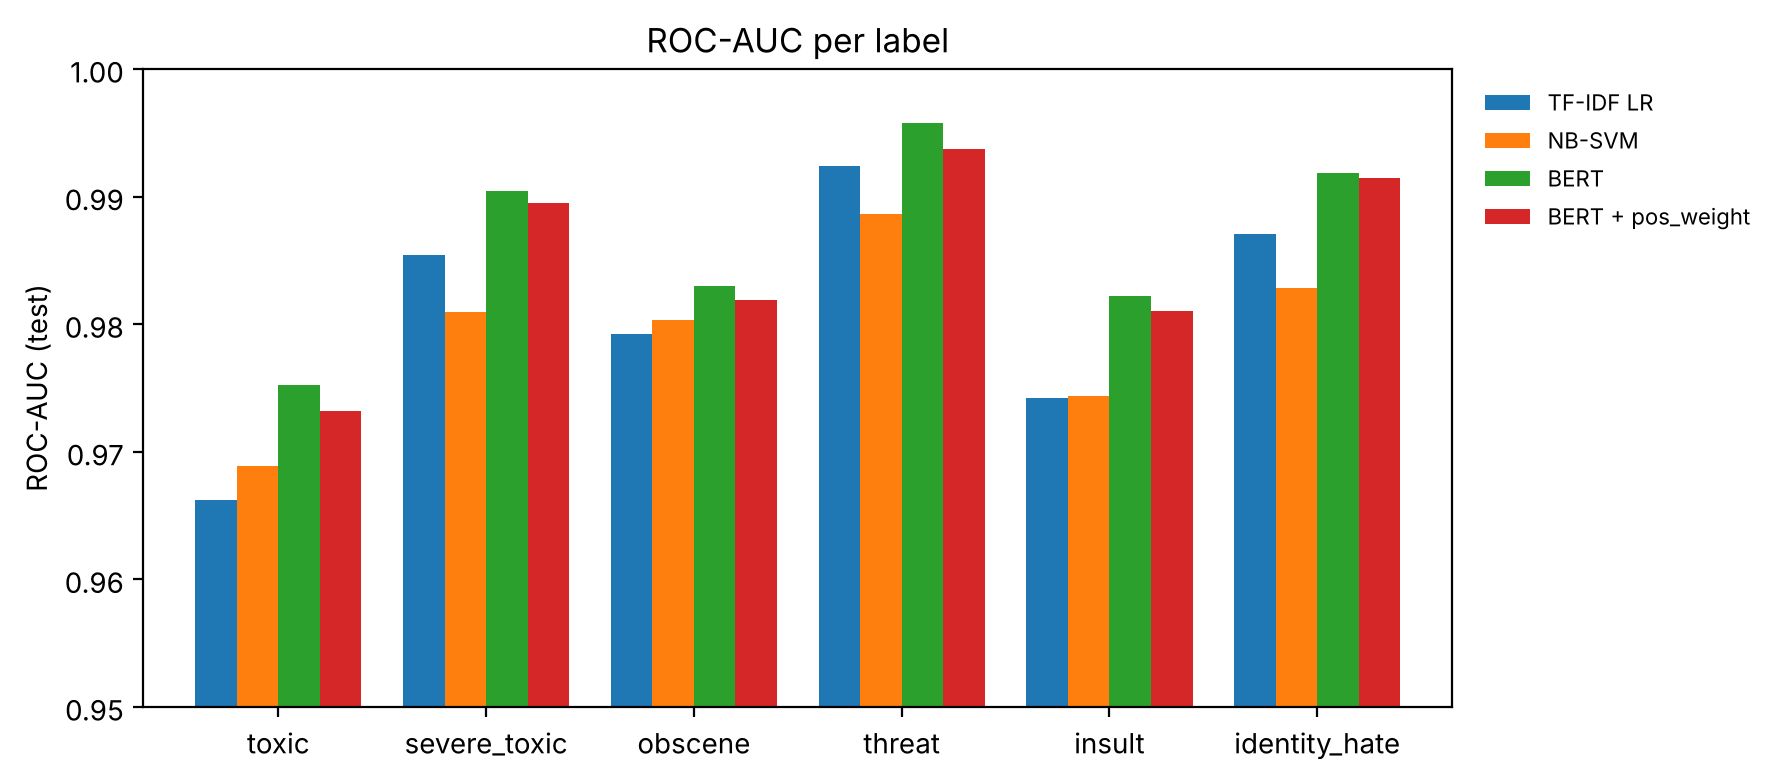

In [11]:
per_label = pd.DataFrame({k: t.loc["all", LABELS] for k, t in tables.items()}).astype(float)
display(per_label.round(4))

ax = per_label.plot.bar(figsize=(9, 4), width=0.8)
ax.set_ylim(0.95, 1.0); ax.set_ylabel("ROC-AUC (test)"); ax.set_title("ROC-AUC per label")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8, frameon=False)
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

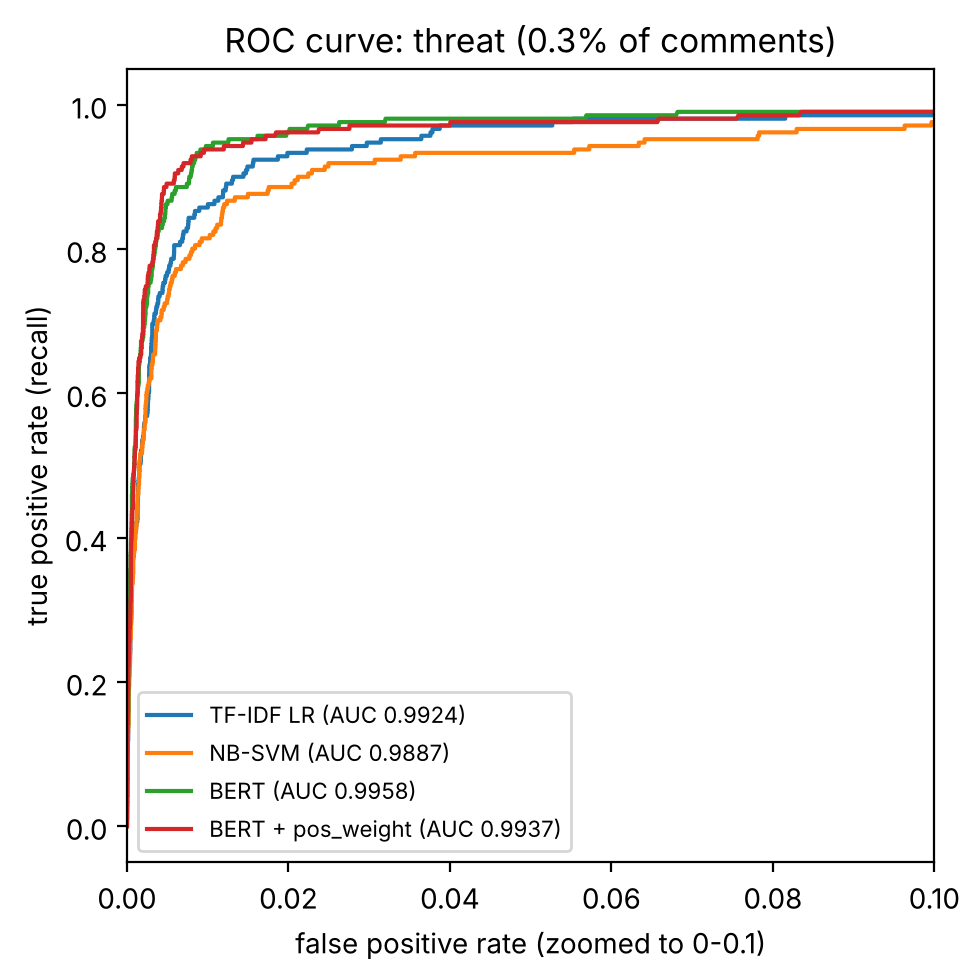

In [12]:
# ROC curves for the rarest label
from sklearn.metrics import roc_curve, roc_auc_score
fig, ax = plt.subplots(figsize=(5, 5))
for k, v in models.items():
    p = pd.read_csv(PREDS / f"{v}_test.csv").merge(test[["id", "threat"]], on="id", suffixes=("_p", ""))
    fpr, tpr, _ = roc_curve(p.threat, p.threat_p)
    ax.plot(fpr, tpr, label=f"{k} (AUC {roc_auc_score(p.threat, p.threat_p):.4f})")
ax.set_xlim(0, 0.1)   # all models are near-perfect beyond FPR 0.1; zoom in where they differ
ax.set_xlabel("false positive rate (zoomed to 0-0.1)"); ax.set_ylabel("true positive rate (recall)")
ax.set_title("ROC curve: threat (0.3% of comments)"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Cut-offs.** Precision, recall and F1 need a yes/no decision. A cut-off of 0.5 misses most rare positives, because models trained on 0.3% threats keep their probabilities low. Each label's cut-off is therefore chosen on the validation fold (max F1) and applied unchanged to the test set. BCR = $\sqrt{\text{TPR} \cdot \text{TNR}}$.

In [13]:
val_truth = train  # fold 0 rows are inside train_clean.csv
for k, v in models.items():
    print(f"== {k}: test metrics at 0.5 vs cut-off chosen on validation")
    display(cutoff_table(PREDS / f"{v}_test.csv", test, PREDS / f"{v}_val.csv", val_truth)
            [["precision", "recall", "f1", "bcr", "tp", "fp", "fn"]].round(3))

== TF-IDF LR: test metrics at 0.5 vs cut-off chosen on validation


precision  recall     f1    bcr    tp    fp    fn
label         cutoff                                                         
toxic         0.5 (0.50)        0.630   0.769  0.692  0.856  4682  2753  1408
              tuned (0.29)      0.539   0.864  0.664  0.893  5263  4499   827
severe_toxic  0.5 (0.50)        0.365   0.316  0.339  0.561   116   202   251
              tuned (0.12)      0.252   0.714  0.373  0.840   262   777   105
obscene       0.5 (0.50)        0.750   0.666  0.706  0.811  2460   818  1231
              tuned (0.20)      0.613   0.813  0.699  0.887  3000  1893   691
threat        0.5 (0.50)        0.650   0.308  0.418  0.555    65    35   146
              tuned (0.08)      0.424   0.697  0.527  0.833   147   200    64
insult        0.5 (0.50)        0.756   0.549  0.636  0.737  1882   609  1545
              tuned (0.21)      0.584   0.758  0.659  0.857  2597  1852   830
identity_hate 0.5 (0.50)        0.719   0.330  0.452  0.574   235    92   477
              tuned (0.20)      0.574   0.563  0.569  0.749   401   297   311

== NB-SVM: test metrics at 0.5 vs cut-off chosen on validation


precision  recall     f1    bcr    tp    fp    fn
label         cutoff                                                         
toxic         0.5 (0.50)        0.617   0.805  0.698  0.873  4901  3044  1189
              tuned (0.31)      0.549   0.874  0.675  0.899  5323  4368   767
severe_toxic  0.5 (0.50)        0.332   0.267  0.296  0.516    98   197   269
              tuned (0.17)      0.269   0.589  0.369  0.764   216   588   151
obscene       0.5 (0.50)        0.726   0.694  0.710  0.826  2562   968  1129
              tuned (0.15)      0.569   0.852  0.682  0.905  3145  2383   546
threat        0.5 (0.50)        0.651   0.265  0.377  0.515    56    30   155
              tuned (0.13)      0.482   0.517  0.499  0.718   109   117   102
insult        0.5 (0.50)        0.742   0.577  0.649  0.755  1978   688  1449
              tuned (0.16)      0.541   0.812  0.649  0.883  2782  2359   645
identity_hate 0.5 (0.50)        0.716   0.372  0.490  0.610   265   105   447
              tuned (0.16)      0.553   0.618  0.584  0.784   440   356   272

== BERT: test metrics at 0.5 vs cut-off chosen on validation


precision  recall     f1    bcr    tp    fp   fn
label         cutoff                                                        
toxic         0.5 (0.50)        0.525   0.928  0.671  0.920  5653  5119  437
              tuned (0.66)      0.583   0.888  0.704  0.910  5408  3873  682
severe_toxic  0.5 (0.50)        0.384   0.485  0.428  0.695   178   286  189
              tuned (0.32)      0.298   0.755  0.427  0.864   277   652   90
obscene       0.5 (0.50)        0.615   0.829  0.706  0.896  3059  1915  632
              tuned (0.46)      0.599   0.841  0.700  0.901  3104  2075  587
threat        0.5 (0.50)        0.584   0.626  0.604  0.790   132    94   79
              tuned (0.40)      0.509   0.706  0.591  0.839   149   144   62
insult        0.5 (0.50)        0.660   0.771  0.711  0.868  2643  1362  784
              tuned (0.39)      0.593   0.827  0.691  0.895  2835  1945  592
identity_hate 0.5 (0.50)        0.689   0.597  0.640  0.771   425   192  287
              tuned (0.36)      0.606   0.698  0.649  0.833   497   323  215

== BERT + pos_weight: test metrics at 0.5 vs cut-off chosen on validation


precision  recall     f1    bcr    tp    fp   fn
label         cutoff                                                        
toxic         0.5 (0.50)        0.433   0.971  0.599  0.917  5916  7761  174
              tuned (0.90)      0.528   0.923  0.672  0.918  5624  5026  466
severe_toxic  0.5 (0.50)        0.167   0.937  0.284  0.955   344  1713   23
              tuned (0.88)      0.249   0.828  0.383  0.904   304   916   63
obscene       0.5 (0.50)        0.442   0.946  0.602  0.936  3491  4413  200
              tuned (0.89)      0.566   0.861  0.683  0.909  3179  2436  512
threat        0.5 (0.50)        0.324   0.905  0.478  0.948   191   398   20
              tuned (0.90)      0.432   0.810  0.563  0.899   171   225   40
insult        0.5 (0.50)        0.410   0.941  0.571  0.932  3224  4636  203
              tuned (0.90)      0.584   0.828  0.685  0.895  2837  2019  590
identity_hate 0.5 (0.50)        0.374   0.890  0.527  0.936   634  1061   78
              tuned (0.90)      0.529   0.775  0.629  0.877   552   492  160

## 5. BERT with `pos_weight` (GPU)

`bert-base-uncased`, 2 epochs, learning rate 2e-5, batch 32, max length 256 (standard settings, not tuned). With `--pos-weight`, a positive example of label *j* counts $w_j = \min(\#\text{neg}_j/\#\text{pos}_j,\ 50)$ times in the binary cross-entropy, so rare labels like threat push the shared encoder as hard as common ones. Cut-offs are chosen afterwards (section 4), because the weighted model's probabilities are shifted upwards.

Both BERT runs (plain and with `pos_weight`) were trained on Kaggle with a T4 GPU on the final preprocessing (about 55 min each); the training log with the per-epoch validation AUC is in `results/bert_training_log.txt`. Each run writes `preds/<tag>_val.csv`, `preds/<tag>_test.csv` and `preds/<tag>_best/`.

In [14]:
if RUN_BERT_PW:
    assert HAS_GPU, "switch the runtime to a GPU first"
    !python train_bert.py --data out --preds preds --pos-weight --tag bert_pw

if (PREDS / "bert_pw_test.csv").exists():
    display(per_label[["BERT", "BERT + pos_weight"]].assign(diff=lambda d: d["BERT + pos_weight"] - d["BERT"]).round(4))
else:
    print("bert_pw predictions not found yet: run this cell on a GPU with RUN_BERT_PW = True")

,BERT,BERT + pos_weight,diff
toxic,0.9753,0.9732,-0.0020
severe_toxic,0.9904,0.9895,-0.0009
obscene,0.9830,0.9819,-0.0011
threat,0.9958,0.9937,-0.0020
insult,0.9822,0.9810,-0.0012
identity_hate,0.9919,0.9914,-0.0004


### Ensemble

`ensemble.py` turns each model's scores into percentile ranks, averages the four models with per-label weights (steps of 0.1, best validation AUC), and picks each label's cut-off on validation (max F1). Test scores are ranked against the validation scores, so a validation cut-off means the same on test.

In [15]:
if RUN_ENSEMBLE:
    !python ensemble.py --preds preds --data out
ens = pd.read_csv("results/ensemble_test_metrics.csv", index_col=0)
ens.round(4)

,tfidf_lr,tfidf_nbsvm,bert,bert_pw,val_auc,test_auc,cutoff,precision,recall,f1,bcr
label,,,,,,,,,,,
toxic,0.1,0.1,0.4,0.4,0.9886,0.9758,0.8973,0.5277,0.9322,0.6739,0.9222
severe_toxic,0.1,0.0,0.7,0.2,0.9929,0.9906,0.9856,0.3100,0.7466,0.4380,0.8599
obscene,0.1,0.0,0.8,0.1,0.9949,0.9837,0.9437,0.6093,0.8404,0.7064,0.9015
threat,0.7,0.2,0.0,0.1,0.9923,0.9933,0.9955,0.4606,0.6919,0.5530,0.8307
insult,0.0,0.1,0.8,0.1,0.9908,0.9829,0.9446,0.6360,0.8016,0.7093,0.8836
identity_hate,0.1,0.0,0.1,0.8,0.9900,0.9922,0.9895,0.5904,0.7247,0.6507,0.8489
mean,NaN,NaN,NaN,NaN,0.9916,0.9864,NaN,0.5223,0.7896,0.6219,0.8745


### Validation vs test

Every model scores lower on test than on validation. One reason: comments with the same strong words are labeled toxic less often in the test set.

In [16]:
rows = []
for k, v in models.items():
    pv = pd.read_csv(PREDS / f"{v}_val.csv").merge(train[["id", *LABELS]], on="id", suffixes=("_p", ""))
    pt = pd.read_csv(PREDS / f"{v}_test.csv").merge(test[["id", *LABELS]], on="id", suffixes=("_p", ""))
    rows.append({"model": k,
                 "val AUC": np.mean([roc_auc_score(pv[c], pv[c + "_p"]) for c in LABELS]),
                 "test AUC": np.mean([roc_auc_score(pt[c], pt[c + "_p"]) for c in LABELS])})
display(pd.DataFrame(rows).set_index("model").round(4))

shift = []
for w in ["fuck", "asshole", "bastard", "idiot", "stupid", "sucks"]:
    a = train.comment_text.str.contains(w, case=False); b = test.comment_text.str.contains(w, case=False)
    shift.append({"word": w, "train n": a.sum(), "train % toxic": train.toxic[a].mean() * 100,
                  "test n": b.sum(), "test % toxic": test.toxic[b].mean() * 100})
pd.DataFrame(shift).set_index("word").round(1)

,val AUC,test AUC
model,,
TF-IDF LR,0.9867,0.9807
NB-SVM,0.9842,0.9793
BERT,0.9887,0.9864
BERT + pos_weight,0.9891,0.9851


,train n,train % toxic,test n,test % toxic
word,,,,
fuck,4406,94.1,2313,67.7
asshole,699,90.3,303,67.3
bastard,362,81.8,204,52.0
idiot,1205,67.6,824,51.8
stupid,1671,61.2,1544,43.3
sucks,253,73.9,332,50.3


## 6. t-SNE of BERT sentence vectors (GPU)

A sample of 4,000 labeled test comments (half clean, rare labels oversampled), embedded with the fine-tuned BERT's `[CLS]` vector and reduced to 2D with t-SNE (lecture 7-1). Each point is coloured by its most specific label.

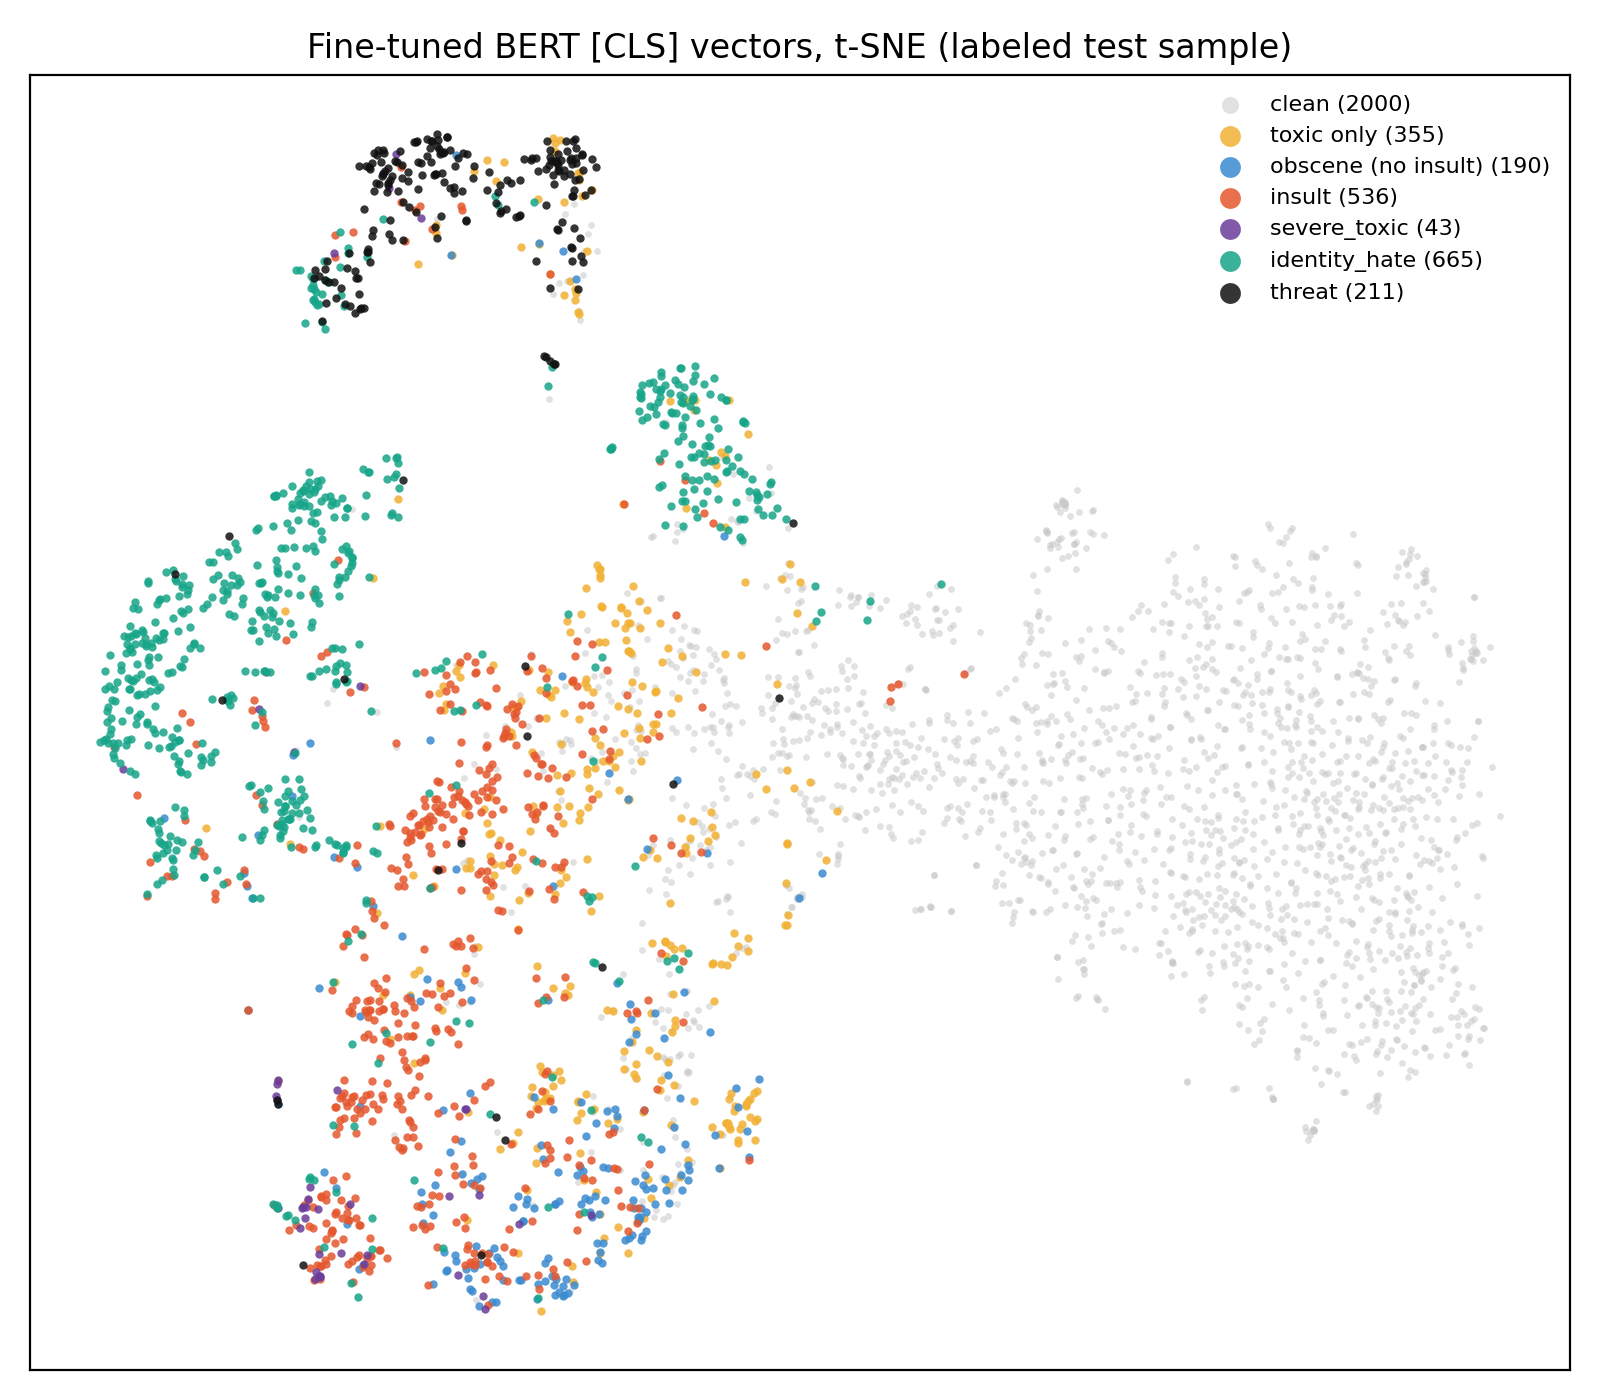

In [17]:
if RUN_TSNE:
    !python tsne_bert.py --model preds/bert_best --data out --n 4000 --out results/tsne_bert.png

if Path("results/tsne_bert.png").exists():
    display(Image("results/tsne_bert.png", width=650))
else:
    print("tsne_bert.png not found yet: run with RUN_TSNE = True (needs preds/bert_best, GPU recommended)")

## 7. Future work: slang detection with fastText

Full write-up: `docs/future_work_slang_detection.md`. fastText (skip-gram, word pieces of 4–6 letters, 10 epochs) is trained on the training comments; 122 words of a public profanity list serve as anchors. A word's score is its average cosine similarity to its 3 most similar anchors. The leave-out test hides 30% of the anchors and checks how well they are separated from frequency-matched normal words.

In [18]:
if RUN_SLANG:
    !wget -q -O ldnoobw_en.txt https://raw.githubusercontent.com/LDNOOBW/List-of-Dirty-Naughty-Obscene-and-Otherwise-Bad-Words/master/en
    !python slang_fasttext.py --data out --profanity ldnoobw_en.txt --out slang

R = Path("results")
lo = pd.read_csv(R / "slang_leaveout.csv")
display(lo.round(3))
print(f"leave-out ROC-AUC {lo.auc.mean():.3f} ± {lo.auc.std():.3f}; best threshold per split "
      f"{lo.threshold.min():.2f}-{lo.threshold.max():.2f}")
anchors = pd.read_csv(R / "slang_anchors.csv")
print(f"anchors used: {anchors.used.sum()} of {len(anchors)} list words in our vocabulary; "
      f"dropped (r <= 0): {', '.join(anchors[~anchors.used].anchor)}")

,split,hidden,normal,auc,threshold,recall,fpr
0,0,36,401,0.944,0.514,0.972,0.212
1,1,36,401,0.964,0.548,0.944,0.102
2,2,36,401,0.954,0.587,0.833,0.050
3,3,36,401,0.970,0.546,0.944,0.087
4,4,36,401,0.961,0.528,0.944,0.155


leave-out ROC-AUC 0.958 ± 0.010; best threshold per split 0.51-0.59
anchors used: 122 of 127 list words in our vocabulary; dropped (r <= 0): nambla, erotic, escort, bondage, santorum


In [19]:
cand = pd.read_csv(R / "slang_candidates_top.csv")
print("top candidates in the training data that are NOT on the profanity list (no swear stem):")
cand[~cand.has_swear_stem].head(20)[["word", "score", "count", "r"]].round(3)

top candidates in the training data that are NOT on the profanity list (no swear stem):


,word,score,count,r
0,masturbates,0.929,5,2.180
3,masturbator,0.884,6,4.125
16,puss,0.855,7,2.690
19,asswhole,0.851,5,2.873
21,sucker,0.850,54,3.811
30,sucka,0.839,5,3.789
31,butthead,0.839,10,2.690
35,arseholes,0.834,6,4.125
39,ballsack,0.833,7,4.259
40,buttface,0.833,6,3.789


In [20]:
new = pd.read_csv(R / "slang_candidates_new_text_top.csv")
print("after updating on 'new text' (the test comments): candidates never seen in training")
new[~new.seen_before & ~new.has_swear_stem].head(20)[["word", "score", "new_text_count"]].round(3)

after updating on 'new text' (the test comments): candidates never seen in training


,word,score,new_text_count
2,nipplesdo,0.841,5
5,pornos,0.815,5
10,wankest,0.807,5
19,buttholes,0.792,7
20,asexual,0.789,10
21,ashole,0.788,5
23,pedophilic,0.787,9
35,vulvas,0.774,6
36,njgw!njgw,0.773,5
44,azzholes,0.766,6


The ranking finds real cuss words missing from the list (`wanker`, `asshat`, `nobhead`), but also spelling look-alikes (`cockpit`, `dickens`) and sexuality words (`asexual`, `pansexual`). The threshold varies between splits, so the final decision is made by a person reviewing the top of the ranking.